# 12 · Comparación final de modelos

A lo largo del proyecto probamos desde predecir la media hasta un transformer con ajuste fino, pasando por bolsas de
palabras, features manuales, embeddings y combinaciones de modelos. Aquí los reunimos en una sola tabla, de mejor a
peor, cada uno en su **versión final**: después del ajuste de hiperparámetros cuando lo hubo.

Todas las cifras usan la misma validación, **Leave-One-Prompt-Out**, con un prompt que el modelo nunca vio, así que son
directamente comparables. La tabla permite leer el recorrido completo: cuánto aporta cada idea respecto a la anterior.

## 1. Predicciones de cada notebook

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(
    (path for path in [Path.cwd(), *Path.cwd().parents]
     if (path / "src").is_dir() and (path / "notebooks").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("No se encontró la raíz del proyecto.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluation import regression_metrics

PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"
TARGETS: list[str] = ["content", "wording"]
PRED_COLUMNS: list[str] = [f"pred_{target}" for target in TARGETS]

# Todas las predicciones out-of-fold en formato largo: una fila por resumen y modelo
oof = pd.concat([pd.read_csv(PROCESSED_DATA_DIR / name) for name in
                 ["08_oof_predictions.csv", "09_deberta_oof_predictions.csv", "11_oof_predictions.csv"]],
                ignore_index=True)
reference = oof.loc[oof["modelo"] == "Dummy (media)", ["student_id", "prompt_id", *TARGETS]].reset_index(drop=True)
assert len(reference) == 7165


def predictions(model: str) -> np.ndarray:
    # Predicciones de un modelo en el mismo orden de resúmenes que `reference`.
    rows = reference[["student_id"]].merge(oof[oof["modelo"] == model], on="student_id", validate="one_to_one")
    return rows[PRED_COLUMNS].to_numpy()


y: np.ndarray = reference[TARGETS].to_numpy()
groups: np.ndarray = reference["prompt_id"].to_numpy()
print("Modelos con predicciones:", oof["modelo"].nunique(), "| resúmenes:", len(reference))

Modelos con predicciones: 14 | resúmenes: 7165


* 08, 09 y 11 guardaron sus predicciones out-of-fold con el mismo formato, así que se pueden juntar con `concat` y
  calcular todas las métricas con la misma función (`src.evaluation.regression_metrics`).
* `validate="one_to_one"` asegura que cada resumen tenga exactamente una predicción por modelo.
* Las predicciones de 07 no se guardaron en el repositorio, así que sus cifras se leen de su tabla de resultados, que
  usa la misma validación.

## 2. Tabla final

Cada modelo aparece **una sola vez, en su versión final**:

| Modelo | Versión que entra a la tabla |
|---|---|
| Fusión mínima + LightGBM | La ajustada con Optuna y validación anidada (11) |
| DeBERTa-v3-base | La elegida en el ajuste del 10: la selección por prompt eligió la configuración original del 09 |
| Promedio 50/50 | DeBERTa elegido + fusión mínima ajustada; el peso 50/50 se mantuvo porque ajustarlo no mejoró |
| BoW y TF-IDF | Los de 07, con `min_df` y `alpha` elegidos con búsqueda agrupada por prompt |
| Resto de 08 | Sin cambios: LightGBM con parámetros fijos y Ridge con `alpha` elegido por `RidgeCV` |

La columna `mcrmse_antes_del_ajuste` muestra el valor previo para los modelos que se ajustaron en 10 y 11.

In [2]:
DEBERTA: str = "DeBERTa-v3-base (fine-tuning)"
FUSION_08: str = "Opción 1: Fusión mínima (A + cos_sim) + LightGBM"
FUSION_11: str = "Fusión mínima + LightGBM ajustado (validación anidada)"
BLEND_11: str = "Promedio 50/50: DeBERTa + fusión ajustada"
FIXED_LGBM: str = "Parámetros fijos de antemano (sin ajuste)"
RIDGE_CV: str = "alpha elegido por RidgeCV en el entrenamiento de cada fold"
GROUPED_07: str = "min_df y alpha con búsqueda agrupada por prompt (anidada)"

# nombre en la tabla: (nombre en los archivos, notebook, cómo se ajustaron los hiperparámetros)
MODELS: dict[str, tuple[str, str, str]] = {
    "Promedio 50/50: DeBERTa + fusión mínima": (
        BLEND_11, "09–11", "Peso 50/50 fijo (ajustarlo no mejoró); componentes en su versión final"),
    "Fusión mínima (features + cos_sim) + LightGBM": (
        FUSION_11, "08 → 11", "Optuna (60 pruebas por búsqueda) con validación anidada por prompt"),
    "Fusión temprana (features + embedding) + LightGBM": (
        "Opción 1: Fusión temprana + LightGBM", "08", FIXED_LGBM),
    "Features manuales + LightGBM": ("A. Features + LightGBM", "08", FIXED_LGBM),
    "DeBERTa-v3-base (fine-tuning)": (
        DEBERTA, "09 → 10", "3 variantes (2 épocas, lr 1e-5, texto fuente); la selección por prompt eligió la original"),
    "Stacking (LightGBM features + Ridge embedding)": (
        "Opción 2: Stacking (LightGBM A + Ridge B)", "08", "Modelos base como en 08; meta-modelo Ridge(alpha=1)"),
    "Fusión temprana (features + embedding PCA) + Ridge": ("Opción 1: Fusión temprana + Ridge", "08", RIDGE_CV),
    "Features manuales + Ridge": ("A. Features + Ridge", "08", RIDGE_CV),
    "Solo largo + Ridge": ("Solo largo + Ridge", "08", RIDGE_CV),
    "Embedding sin tema + PCA(16) + Ridge": ("B. Embedding sin tema + PCA(16) + Ridge", "08", RIDGE_CV),
    "Embedding sin tema + Ridge": ("B. Embedding sin tema + Ridge", "08", RIDGE_CV),
    "Embedding crudo + Ridge": ("B. Embedding crudo + Ridge", "08", RIDGE_CV),
    "Dummy (media)": ("Dummy (media)", "08", "Sin hiperparámetros"),
}
# Valor antes del ajuste, para los modelos que se ajustaron en 10 y 11
BEFORE: dict[str, np.ndarray] = {
    "Promedio 50/50: DeBERTa + fusión mínima": 0.5 * predictions(DEBERTA) + 0.5 * predictions(FUSION_08),
    "Fusión mínima (features + cos_sim) + LightGBM": predictions(FUSION_08),
    "DeBERTa-v3-base (fine-tuning)": predictions(DEBERTA),
}


def spread_between_prompts(pred: np.ndarray) -> float:
    # Desviación estándar del MCRMSE de los 4 prompts: qué tanto cambia el error de un prompt a otro.
    return float(np.std([regression_metrics(y[groups == g], pred[groups == g])["mcrmse"]
                         for g in np.unique(groups)], ddof=1))


rows: list[dict] = []
for name, (source, notebook, tuning) in MODELS.items():
    pred = predictions(source)
    metrics = regression_metrics(y, pred)
    rows.append({"modelo": name, "notebook": notebook, "ajuste_hiperparametros": tuning,
                 "rmse_content": metrics["rmse_content"], "r2_content": metrics["r2_content"],
                 "rmse_wording": metrics["rmse_wording"], "r2_wording": metrics["r2_wording"],
                 "mcrmse": metrics["mcrmse"],
                 "mcrmse_antes_del_ajuste": regression_metrics(y, BEFORE[name])["mcrmse"] if name in BEFORE else np.nan,
                 "desviacion_entre_prompts": spread_between_prompts(pred)})

lexical = pd.read_csv(TABLES_DIR / "07_tfidf_grouped_results.csv")
lexical = lexical[lexical["modelo"] != "Dummy media"]   # el Dummy ya está, calculado en 08
for record in lexical.to_dict("records"):
    rows.append({"modelo": record["modelo"], "notebook": "07", "ajuste_hiperparametros": GROUPED_07,
                 **{key: record[key] for key in ["rmse_content", "r2_content", "rmse_wording", "r2_wording", "mcrmse"]},
                 "mcrmse_antes_del_ajuste": np.nan,
                 "desviacion_entre_prompts": record["desviacion_mcrmse_entre_prompts"]})

final = pd.DataFrame(rows).sort_values("mcrmse").reset_index(drop=True)
dummy = final.loc[final["modelo"] == "Dummy (media)", "mcrmse"].item()
final.insert(0, "posicion", np.arange(1, len(final) + 1))
final["mejora_vs_dummy_%"] = 100 * (1 - final["mcrmse"] / dummy)
final.to_csv(TABLES_DIR / "12_final_comparison.csv", index=False)

with pd.option_context("display.max_colwidth", 90, "display.width", 250):
    display(final.set_index("posicion").round(3))

,modelo,notebook,ajuste_hiperparametros,rmse_content,r2_content,rmse_wording,r2_wording,mcrmse,mcrmse_antes_del_ajuste,desviacion_entre_prompts,mejora_vs_dummy_%
posicion,,,,,,,,,,,
1,Promedio 50/50: DeBERTa + fusión mínima,09–11,Peso 50/50 fijo (ajustarlo no mejoró); componentes en su versión final,0.433,0.828,0.626,0.635,0.529,0.529,0.048,49.602
2,Fusión mínima (features + cos_sim) + LightGBM,08 → 11,Optuna (60 pruebas por búsqueda) con validación anidada por prompt,0.478,0.790,0.669,0.583,0.573,0.576,0.081,45.390
3,Fusión temprana (features + embedding) + LightGBM,08,Parámetros fijos de antemano (sin ajuste),0.487,0.782,0.668,0.584,0.578,NaN,0.094,44.991
4,Features manuales + LightGBM,08,Parámetros fijos de antemano (sin ajuste),0.485,0.784,0.677,0.573,0.581,NaN,0.085,44.644
5,DeBERTa-v3-base (fine-tuning),09 → 10,"3 variantes (2 épocas, lr 1e-5, texto fuente); la selección por prompt eligió la original",0.462,0.804,0.740,0.490,0.601,0.601,0.057,42.791
6,Stacking (LightGBM features + Ridge embedding),08,Modelos base como en 08; meta-modelo Ridge(alpha=1),0.505,0.765,0.701,0.542,0.603,NaN,0.080,42.545
7,Fusión temprana (features + embedding PCA) + Ridge,08,alpha elegido por RidgeCV en el entrenamiento de cada fold,0.504,0.767,0.710,0.530,0.607,NaN,0.076,42.194
8,Features manuales + Ridge,08,alpha elegido por RidgeCV en el entrenamiento de cada fold,0.510,0.761,0.713,0.526,0.611,NaN,0.082,41.762
9,Solo largo + Ridge,08,alpha elegido por RidgeCV en el entrenamiento de cada fold,0.561,0.711,0.862,0.307,0.712,NaN,0.087,32.227


* `MODELS` relaciona el nombre que aparece en la tabla con el nombre que tiene el modelo en los archivos de
  predicciones. Así la tabla final usa nombres más claros sin cambiar los archivos de los notebooks anteriores.
* `ddof=1` calcula la desviación estándar muestral, igual que la columna equivalente de 08.
* `mejora_vs_dummy_%` es cuánto baja el MCRMSE respecto a predecir siempre la media (100 % sería error cero).
* En el promedio 50/50, la versión final usa la fusión ajustada (0.5291) y la de antes la fusión de 08 (0.5285): la
  diferencia es menor a 0.001 y no cambia ninguna conclusión.

La tabla deja tres candidatos claros para el modelo final: el **promedio 50/50**, la **fusión mínima con LightGBM**
(el mejor modelo individual) y **DeBERTa** (el único que lee el texto). El resto queda descartado: los modelos con
Ridge y el stacking quedan por debajo de la fusión con LightGBM, y los léxicos y los embeddings solos ni se acercan.
Las siguientes secciones comparan a los tres candidatos con más detalle antes de elegir.

## 3. Los tres finalistas, prompt por prompt

Un MCRMSE global puede esconder que un modelo gana mucho en un prompt y pierde en los demás. Como cada prompt es un
texto distinto, lo que importa es que el modelo elegido funcione bien **con cualquier texto nuevo**, así que lo
comparamos prompt por prompt.

modelo,Promedio 50/50,Fusión mínima + LightGBM,DeBERTa-v3-base
prompt,,,
Egyptian Social Structure,0.577,0.625,0.634
Excerpt from The Jungle,0.471,0.508,0.516
On Tragedy,0.512,0.518,0.625
The Third Wave,0.561,0.672,0.627


Prompts en los que el promedio tiene el menor error: 4 de 4


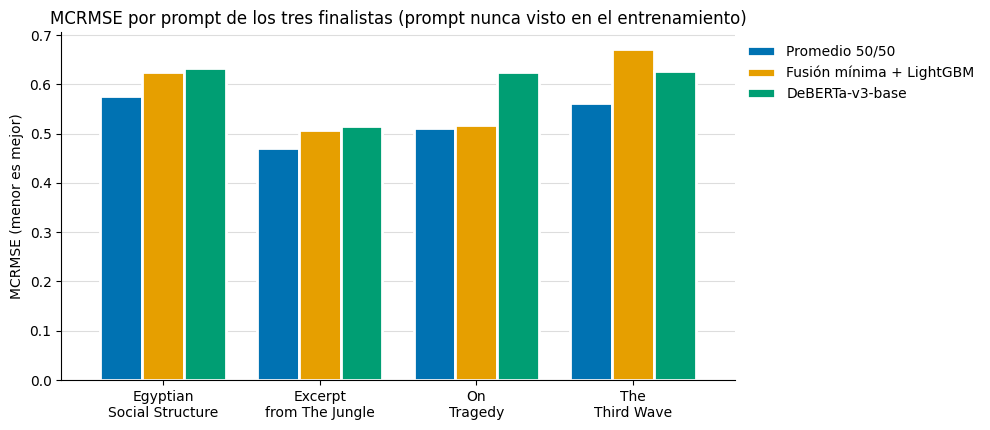

In [3]:
import matplotlib.pyplot as plt

FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
PROMPT_TITLES: dict[str, str] = (pd.read_csv(PROJECT_ROOT / "data" / "interim" / "prompts_train_clean.csv")
                                 .set_index("prompt_id")["prompt_title"].to_dict())

# Nombre corto de cada finalista: predicciones de su versión final
FINALISTS: dict[str, np.ndarray] = {
    "Promedio 50/50": predictions(BLEND_11),
    "Fusión mínima + LightGBM": predictions(FUSION_11),
    "DeBERTa-v3-base": predictions(DEBERTA),
}
COLORS: dict[str, str] = {"Promedio 50/50": "#0072B2", "Fusión mínima + LightGBM": "#E69F00",
                          "DeBERTa-v3-base": "#009E73"}

by_prompt_rows: list[dict] = []
for name, pred in FINALISTS.items():
    for prompt_id in np.unique(groups):
        mask = groups == prompt_id
        metrics = regression_metrics(y[mask], pred[mask])
        by_prompt_rows.append({"modelo": name, "prompt": PROMPT_TITLES[prompt_id],
                               "rmse_content": metrics["rmse_content"], "rmse_wording": metrics["rmse_wording"],
                               "mcrmse": metrics["mcrmse"]})
finalists_by_prompt = pd.DataFrame(by_prompt_rows)
finalists_by_prompt.to_csv(TABLES_DIR / "12_finalists_by_prompt.csv", index=False)

pivot = finalists_by_prompt.pivot(index="prompt", columns="modelo", values="mcrmse")[list(FINALISTS)]
display(pivot.round(3))
print("Prompts en los que el promedio tiene el menor error:",
      int((pivot.idxmin(axis=1) == "Promedio 50/50").sum()), "de", len(pivot))

fig, ax = plt.subplots(figsize=[10, 4.4])
pivot.plot.bar(ax=ax, width=0.8, color=[COLORS[name] for name in pivot.columns], edgecolor="white", linewidth=2)
ax.set(title="MCRMSE por prompt de los tres finalistas (prompt nunca visto en el entrenamiento)",
       xlabel="", ylabel="MCRMSE (menor es mejor)")
ax.set_xticklabels([label.get_text().replace(" ", "\n", 1) for label in ax.get_xticklabels()], rotation=0)
ax.grid(axis="y", color="#dddddd", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout()
fig.savefig(FIGURES_DIR / "12_finalists_by_prompt.png", dpi=150, bbox_inches="tight")
plt.show()

* `pivot(index=..., columns=..., values=...)` pasa la tabla de formato largo (una fila por modelo y prompt) a una
  matriz prompt × modelo; `idxmin(axis=1)` da, para cada prompt, el modelo con menor error.
* Los títulos de los prompts se parten en la primera palabra (`replace(" ", "\n", 1)`) para que no se encimen en el eje.

**Lectura.** El promedio tiene el menor error en **los cuatro prompts**: su ventaja no depende de un texto en
particular. Lo más notable es dónde gana. En *The Third Wave* la fusión tiene su peor resultado (0.672) y DeBERTa lo
hace mejor (0.627); en *On Tragedy* pasa lo contrario: la fusión (0.518) supera con holgura a DeBERTa (0.625). El
promedio queda por debajo de los dos en ambos casos (0.561 y 0.512), porque cuando uno de los modelos falla, el otro
compensa.

## 4. ¿La ventaja es real o es suerte?

Con 7,165 resúmenes, una diferencia de 0.04 en el MCRMSE podría parecer pequeña. Para saber si es estable, usamos un
**bootstrap pareado**: se sortean con reemplazo los resúmenes de cada prompt, se recalcula el MCRMSE de los dos modelos
sobre **la misma** muestra y se guarda la diferencia. Repetido 2,000 veces, da un intervalo de confianza del 95 %
para la diferencia.

También medimos la **correlación de los errores** de la fusión y de DeBERTa: si los dos se equivocaran en los mismos
resúmenes, promediarlos no ayudaría.

In [4]:
def mcrmse(y_true: np.ndarray, y_pred: np.ndarray) -> np.ndarray:
    # MCRMSE sobre el penúltimo eje; acepta un lote de muestras bootstrap de forma (repeticiones, filas, 2).
    return np.sqrt(((y_true - y_pred) ** 2).mean(axis=-2)).mean(axis=-1)


rng = np.random.default_rng(42)
N_BOOTSTRAP: int = 2000
# Índices sorteados dentro de cada prompt, para que cada muestra conserve el peso de cada texto
prompt_indices = [np.flatnonzero(groups == prompt_id) for prompt_id in np.unique(groups)]
samples = np.concatenate([rng.choice(index, size=(N_BOOTSTRAP, len(index))) for index in prompt_indices], axis=1)

best = FINALISTS["Promedio 50/50"]
bootstrap_rows: list[dict] = []
for rival in ["Fusión mínima + LightGBM", "DeBERTa-v3-base"]:
    difference = mcrmse(y[samples], best[samples]) - mcrmse(y[samples], FINALISTS[rival][samples])
    low, high = np.percentile(difference, [2.5, 97.5])
    bootstrap_rows.append({"comparacion": f"Promedio 50/50 − {rival}",
                           "diferencia_mcrmse": mcrmse(y, best) - mcrmse(y, FINALISTS[rival]),
                           "ic95_inferior": low, "ic95_superior": high,
                           "%_muestras_donde_gana_el_promedio": 100 * (difference < 0).mean()})
display(pd.DataFrame(bootstrap_rows).round(4))

residual_fusion = y - FINALISTS["Fusión mínima + LightGBM"]
residual_deberta = y - FINALISTS["DeBERTa-v3-base"]
for j, target in enumerate(TARGETS):
    print(f"Correlación de errores fusión–DeBERTa en {target}: "
          f"{np.corrcoef(residual_fusion[:, j], residual_deberta[:, j])[0, 1]:.2f}")

,comparacion,diferencia_mcrmse,ic95_inferior,ic95_superior,%_muestras_donde_gana_el_promedio
0,Promedio 50/50 − Fusión mínima + LightGBM,-0.0442,-0.0495,-0.0387,100.0
1,Promedio 50/50 − DeBERTa-v3-base,-0.0715,-0.0782,-0.0650,100.0


Correlación de errores fusión–DeBERTa en content: 0.70
Correlación de errores fusión–DeBERTa en wording: 0.65


* `rng.choice(index, size=(N_BOOTSTRAP, len(index)))` sortea de una sola vez las 2,000 muestras de un prompt; al
  concatenarlas por columnas, cada fila de `samples` es una muestra completa con el mismo número de resúmenes por
  prompt que los datos originales.
* `y[samples]` tiene forma (2000, 7165, 2), por eso `mcrmse` promedia sobre `axis=-2` (los resúmenes) y luego sobre
  `axis=-1` (los dos objetivos): calcula las 2,000 métricas sin un bucle.
* Es **pareado** porque los dos modelos se evalúan en los mismos resúmenes de cada muestra; así se mide la diferencia
  entre ellos y no la variación de los datos.

**Lectura.** El intervalo de confianza de las dos diferencias queda **completamente por debajo de cero**, y el
promedio gana en el 100 % de las muestras: su ventaja no se explica por cuáles resúmenes tocaron. La correlación de
los errores (0.70 en `content` y 0.65 en `wording`) explica por qué: los dos modelos se equivocan parecido, pero no
igual. La fusión mira el largo, el vocabulario y la similitud con el texto fuente; DeBERTa lee el resumen completo.
Al promediar, la parte del error que no comparten se cancela.

Una advertencia: el bootstrap sortea resúmenes, no prompts. La duda de cómo se comportará el modelo con un texto
nuevo la responde mejor la sección anterior, donde el promedio gana en los cuatro prompts.

## 5. ¿Dónde se equivoca el modelo elegido?

Antes de recomendar un modelo conviene saber en qué casos falla. Revisamos dos cosas del promedio: cómo cambia el
error según el largo del resumen y si tiende a acercar las notas extremas hacia el centro.

In [5]:
summaries = pd.read_csv(PROJECT_ROOT / "data" / "interim" / "summaries_train_clean.csv", usecols=["student_id", "text"])
word_count = reference[["student_id"]].merge(summaries, on="student_id", validate="one_to_one")["text"].str.split().str.len()

errors = pd.DataFrame({
    "largo": pd.qcut(word_count, 5, labels=["muy corto", "corto", "medio", "largo", "muy largo"]),
    **{f"sesgo_{target}": best[:, j] - y[:, j] for j, target in enumerate(TARGETS)},
    **{f"nota_real_{target}": pd.qcut(y[:, j], 5, labels=["la más baja", "baja", "media", "alta", "la más alta"])
       for j, target in enumerate(TARGETS)},
})
rmse = lambda values: float(np.sqrt((values ** 2).mean()))

by_length = errors.groupby("largo", observed=True).agg(
    palabras=("largo", lambda rows: f"{word_count[rows.index].min()}–{word_count[rows.index].max()}"),
    rmse_content=("sesgo_content", rmse), rmse_wording=("sesgo_wording", rmse))
print("Error del promedio según el largo del resumen (quintiles de palabras):")
display(by_length.round(3))

bias_by_score = pd.DataFrame({
    target: errors.groupby(f"nota_real_{target}", observed=True)[f"sesgo_{target}"].mean() for target in TARGETS
})
bias_by_score.index.name = "quintil de la nota real"
print("Sesgo medio (predicción − nota real) según la nota real:")
display(bias_by_score.round(3))

Error del promedio según el largo del resumen (quintiles de palabras):


,palabras,rmse_content,rmse_wording
largo,,,
muy corto,22–36,0.327,0.525
corto,37–49,0.392,0.582
medio,50–69,0.362,0.578
largo,70–104,0.442,0.633
muy largo,105–647,0.596,0.785


Sesgo medio (predicción − nota real) según la nota real:


,content,wording
quintil de la nota real,,
la más baja,0.367,0.701
baja,0.110,0.450
media,-0.023,0.227
alta,-0.049,0.000
la más alta,-0.260,-0.292


* `pd.qcut(..., 5)` divide en cinco grupos con el mismo número de resúmenes (quintiles); `observed=True` evita grupos
  vacíos al agrupar por una columna categórica.
* El **sesgo** es predicción menos nota real: positivo significa que el modelo da más nota de la merecida.
* `rmse` se aplica al sesgo de cada grupo, porque la raíz del promedio de los sesgos al cuadrado es el RMSE.

**Lectura.**
1. **Los resúmenes muy largos son los más difíciles.** En el quintil de 105 a 647 palabras, el RMSE sube a 0.596 en
   `content` y 0.785 en `wording`, contra 0.327 y 0.525 en los más cortos. Hay menos ejemplos con ese largo, y el
   largo, la señal más fuerte del modelo, ya no separa bien los buenos de los malos: un resumen largo puede ser
   completo o copiar el texto fuente.
2. **El modelo comprime los extremos.** A los peores resúmenes les da más nota de la que tienen (+0.37 en `content` y
   +0.70 en `wording`) y a los mejores, menos (−0.26 y −0.29). Es la regresión a la media típica de un modelo que
   minimiza el error cuadrático, y en `wording` es más fuerte. En la práctica, el modelo ordena
   bien los resúmenes, pero no conviene leer sus notas extremas al pie de la letra.

## 6. Costo de cada finalista

El error no es lo único que cuenta. El modelo elegido se va a empaquetar en una aplicación, así que también importa
cuánto cuesta entrenarlo, instalarlo y usarlo con un resumen nuevo.

| | Promedio 50/50 | Fusión mínima + LightGBM | DeBERTa-v3-base |
|---|---|---|---|
| MCRMSE (LOPO) | **0.529** | 0.573 | 0.601 |
| Entrenar el modelo final con todos los datos | unos 11 min en GPU (DeBERTa) + segundos (LightGBM) | segundos en CPU | unos 11 min en GPU |
| Hardware para entrenar | GPU (Colab T4 basta) | CPU | GPU |
| Predecir un resumen nuevo | CPU, alrededor de un segundo más la carga inicial del modelo | CPU, instantáneo | CPU, alrededor de un segundo más la carga inicial del modelo |
| Lo que hay que instalar y guardar | `torch`, `transformers`, unos 700 MB de pesos y `en_core_web_md` | `en_core_web_md` (unos 40 MB) y un archivo de pocos MB | `torch`, `transformers` y unos 700 MB de pesos |
| Puede explicar su nota | solo en parte | sí: largo, vocabulario, similitud con el texto fuente | no |
| Necesita el texto fuente | sí (la fusión mide la similitud con él) | sí | no |

* Los tiempos de entrenamiento vienen del notebook 09: entre 7 y 9 minutos por fold en una T4 con unos 5,400
  resúmenes. Con los 7,165 resúmenes, una sola corrida toma alrededor de 11 minutos.
* DeBERTa solo se entrena una vez. Después, predecir un resumen no requiere GPU, pero sí cargar el modelo completo en
  memoria.

## 7. Decisión: el mejor modelo y el modelo para la aplicación

La comparación responde a dos preguntas distintas, y cada una tiene su respuesta:

| Pregunta | Modelo | MCRMSE |
|---|---|---|
| ¿Cuál predice mejor con un texto nunca visto? | **Promedio 50/50** de DeBERTa y la fusión mínima | 0.529 |
| ¿Cuál usamos en la aplicación? | **Fusión mínima + LightGBM ajustado** | 0.573 |

### El mejor modelo del proyecto: el promedio 50/50

1. **Es el más preciso.** Con un prompt nunca visto, su MCRMSE es 0.529, un 7.7 % menos que el mejor modelo
   individual (0.573) y la mitad del error de predecir siempre la media (1.050). Explica el 83 % de la varianza de
   `content` y el 64 % de la de `wording`.
2. **Gana en los cuatro prompts** (sección 3), así que la mejora no depende de un texto en particular.
3. **Es el más estable.** La desviación de su error entre prompts es 0.048, contra 0.081 de la fusión y 0.057 de
   DeBERTa.
4. **Ataca el punto débil del proyecto.** `wording` fue siempre el objetivo más difícil. El promedio baja su RMSE a
   0.626, contra 0.669 de la fusión y 0.740 de DeBERTa.
5. **La ventaja es robusta** (sección 4). El intervalo del bootstrap queda por debajo de cero: los dos modelos ven
   cosas distintas del resumen y sus errores solo se correlacionan en parte.
6. **Su cifra es honesta.** El peso 50/50 se fijó antes de ver resultados. Ajustarlo no mejoró la selección anidada
   (0.532 contra 0.529).

### El modelo de la aplicación: la fusión mínima con LightGBM

Para la aplicación pesa también la facilidad de empaquetar el modelo (sección 6), y ahí la fusión mínima es mucho
mejor opción:

1. **Es el mejor modelo individual** (0.573), mejor que DeBERTa solo (0.601) y que el stacking (0.603).
2. **Es liviano.** Necesita `en_core_web_md` (unos 40 MB) y un archivo de pocos MB con los dos LightGBM. El promedio
   exige además `torch`, `transformers` y unos 700 MB de pesos de DeBERTa.
3. **Se entrena en local, en segundos**, con los hiperparámetros del notebook 11. El promedio obliga a reentrenar
   DeBERTa en una GPU de Colab y a descargar sus pesos.
4. **Predice al instante en cualquier CPU**, sin cargar un transformer en memoria.
5. **Tiene menos puntos de falla.** Es un solo modelo y sus dependencias ya están en `requirements.txt`.
6. **Puede explicar su nota.** Se basa en features con significado (largo, vocabulario, similitud con el texto
   fuente), así que la aplicación puede mostrar qué influyó en la predicción. DeBERTa es una caja negra.

**Lo que se pierde:** 0.044 de MCRMSE. Se nota sobre todo en `wording`, con un RMSE de 0.669 contra 0.626 del
promedio. Es un costo razonable a cambio de una aplicación liviana, rápida y estable. Si más adelante la aplicación
se despliega en un servidor con suficiente memoria, se puede cambiar al promedio 50/50 sin modificar nada más: los
dos modelos reciben el mismo resumen y el mismo texto fuente.

### Por qué no los demás

* **DeBERTa solo** es el mejor en `content` de los modelos individuales (0.462), pero el peor de los tres finalistas
  en `wording` (0.740), y además es el más caro de empaquetar. Ajustarlo (2 épocas, lr 1e-5, texto fuente) no lo
  mejoró.
* **El stacking** (0.603) y **la fusión temprana** (0.578) combinan modelos de forma más elaborada y aun así quedan
  peor que el promedio simple de dos modelos distintos: aquí ayudó más la diversidad de los modelos que la forma de
  combinarlos.

### Qué falta para usarlo en la aplicación

1. Entrenar la fusión mínima con los 7,165 resúmenes y los hiperparámetros elegidos en el 11, y guardarla.
2. Para cada resumen nuevo: calcular las features y la similitud con el texto fuente, y predecir `content` y
   `wording`.

### Límites que hay que conocer

* El error cambia según el texto: entre 0.51 y 0.67 en los cuatro prompts para la fusión mínima. Con un texto muy
  distinto a estos cuatro, podría ser mayor.
* Se entrenó con **cuatro textos en inglés**, resúmenes de estudiantes de 3.º a 12.º grado, de 22 a 647 palabras, y
  con la escala de notas de CommonLit. Fuera de ese rango (otro idioma, textos muy cortos o muy largos), sus
  predicciones no son confiables.
* Los resúmenes muy largos son los más difíciles, y las notas extremas se acercan al centro (sección 5). El modelo
  ordena bien los resúmenes, pero las notas muy altas o muy bajas deben leerse con cuidado.


El mejor modelo del proyecto es el **promedio 50/50 de DeBERTa y la fusión mínima con LightGBM**: MCRMSE 0.529 con
un prompt nunca visto, la mitad del error de predecir la media, el mejor en los cuatro prompts y el más estable entre
ellos. Para la aplicación usamos la **fusión mínima con LightGBM** (0.573). Pierde 0.044 de error, pero es liviana,
se entrena en segundos, predice al instante en cualquier CPU y puede explicar sus notas.

La tabla resume también las lecciones del recorrido:

* **El largo del resumen es la señal más fuerte.** Solo con el largo, el error baja de 1.050 a 0.712.
* **Las palabras por sí solas no generalizan a textos nuevos**, porque dependen del tema. BoW y TF-IDF quedan cerca
  de la media, y los embeddings sin features, peor que ella.
* **`content` es más fácil de predecir que `wording`** en todos los modelos.
* **Ajustar hiperparámetros apenas movió los resultados** (0.576 → 0.573 en la fusión y ninguna mejora en DeBERTa).
* **Combinar modelos distintos rindió más que perfeccionar uno solo.** El mayor salto al final del proyecto vino de
  promediar dos modelos que se equivocan de forma diferente.